# The score, the null model and the interval: judging a prediction when the campaign is held out

**Question:** What does a score mean when the campaign is held out, and how wide is its honest interval?

**Level 2: The method in practice** · Needs: 04-benchmark-protocol/01-three-ways-to-split-the-same-97-blasts · Reading time: about 35 minutes

## Objectives

A number such as "R2 = 0.94" means nothing until the statistic is named, a baseline stands beside it and the uncertainty is stated. This notebook builds the three things the product reports with every score, on predictors that are really held out by campaign.

By the end you will have:

- seen two statistics that share a name give different numbers for the same predictions, and chosen one;
- scored the null model and three learned predictors with each campaign held out, and found why the null is a poor yardstick;
- built a 95 percent interval that resamples blasts and one that resamples campaigns, and measured how much wider the honest one is;
- found which campaigns decide the pooled score, which is the reason the interval is wide.

## Setup

Install the packages with the exact pins of `notebooks/requirements.txt`. The engine is `blastfrag`, published on PyPI; the other packages are its numerical base and the plotting library.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

One cell does all the preparation: it imports the packages, prints their installed versions so the output records which engine produced every number below, defines the table helper and loads the 97 training blasts.

In [1]:
# Imports, the versions behind every number below, a small table helper and the corpus
from importlib.metadata import version

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")


def show_table(columns, rows):
    # pandas is not part of the notebook environment, so a table is a plain HTML table
    head = "".join(f"<th>{c}</th>" for c in columns)
    body = "".join("<tr>" + "".join(f"<td>{v}</td>" for v in row) + "</tr>" for row in rows)
    display(HTML(f"<table><thead><tr>{head}</tr></thead><tbody>{body}</tbody></table>"))


train = bf.load_training_corpus()

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Data

| Source | Owner and URL | Licence class | File the notebook reads |
|---|---|---|---|
| The 97 blasts | Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 | numeric facts reused with citation; the article never ships | the corpus inside the `blastfrag` wheel |
| The 12 published hold-out blasts | Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (Tables 4 and 5) | numeric facts reused with citation; the article never ships | inside the `blastfrag` wheel, `bf.load_holdout()` |

Every number below is recomputed from the 97 training blasts and the 12 hold-out blasts; the notebook reads no baked score.

## Method

**The statistic.** Two quantities carry the name R2 in this literature, and the engine reports each under its own name. `pearson_r2` is the squared correlation of predicted against measured; it is blind to a constant offset or a wrong scale. `r2_identity = 1 - sum((measured - predicted)^2) / sum((measured - mean(measured))^2)` is the variance explained about the identity line, and it is negative when the predictions are worse than the mean of the measurements.

**The null.** A model that predicts the mean measured size of its training rows and uses no input. It is refitted inside every fold, as any model must be.

**The interval.** A bootstrap that resamples the unit of independence. Blasts of one campaign share a rock mass, a rig and an explosive supply, so under a protocol that holds out campaigns the independent unit is the campaign (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881). What to look for: how far apart the two statistics can be, whether the null sits at zero as one would expect, and how many times wider the campaign interval is.

### Step 1: one prediction set, two statistics

The 12 hold-out blasts of Kulatilake, Hudaverdi and Wu 2012 are the set on which the literature reports R2. The cell scores the classical arm on them with `score`, which returns both statistics, and prints their ratio.

In [2]:
# Two statistics on the same predictions: the classical arm on the 12 published hold-out blasts
holdout = bf.load_holdout()
classical = bf.default_arms()["kuznetsov"]().fit(train)
published_set = bf.score(holdout, classical.predict(holdout))
rows = [
    ("pearson_r2", f"{published_set.pearson_r2:.4f}", "squared correlation of predicted against measured"),
    ("r2_identity", f"{published_set.r2_identity:.4f}", "variance explained about the identity line"),
    ("RMSE (m)", f"{published_set.rmse_m:.4f}", "typical error in the unit of the size"),
]
show_table(["statistic", "value", "what it measures"], rows)
ratio = published_set.pearson_r2 / published_set.r2_identity
print(f"blasts scored: {published_set.n_scored} | ratio of the two statistics: {ratio:.2f}")

statistic,value,what it measures
pearson_r2,0.5674,squared correlation of predicted against measured
r2_identity,0.2284,variance explained about the identity line
RMSE (m),0.1282,typical error in the unit of the size


blasts scored: 12 | ratio of the two statistics: 2.48


The same 12 predictions score 0.5674 as a squared correlation and 0.2284 as variance explained about the identity line, a ratio of 2.48, with a root-mean-square error of 0.1282 m. Nothing in the predictions changed between the two numbers; the squared correlation forgives a wrong scale or a constant offset, and the identity-line statistic charges for both. A paper that reports "R2 = 0.57" and one that reports "R2 = 0.23" may describe the same predictor. The table does not say which statistic is right in general: the product's criterion is written on `r2_identity`, because a user needs the predicted size itself, and `pearson_r2` is reported beside it so that the two can be compared with the literature.

### Step 2: every campaign held out in turn

From here on the unit is the campaign. The cell trains the null and three learned predictors (gradient boosting, a random forest and the stacking ensemble) on nine campaigns, predicts the tenth, and collects the out-of-fold prediction of all 97 blasts. `default_arms` returns factories, so each fold gets a fresh model.

In [3]:
# Leave one site out for the null and three learned predictors, collecting every out-of-fold prediction
factories = bf.default_arms()
names = ["null", "xgboost", "random-forest", "stacking"]
tested, predictions = [], {name: [] for name in names}
for fold in bf.leave_one_site_out(train):
    tested += list(fold.test)
    for name in names:
        model = factories[name]().fit(fold.train)
        predictions[name] += model.predict(fold.test)
rows = []
for name in names:
    abstained = sum(p.abstained for p in predictions[name])
    rows.append((name, factories[name]().tier, len(predictions[name]), abstained))
show_table(["predictor", "tier", "out-of-fold predictions", "abstentions"], rows)

predictor,tier,out-of-fold predictions,abstentions
null,control,97,0
xgboost,learned,97,0
random-forest,learned,97,0
stacking,learned,97,0


All four predictors answer every one of the 97 blasts, with no abstention, so the four scores that follow are over the same rows and need no row-set caveat. Each blast is predicted by a model that never saw its campaign: the 97 values are the out-of-fold predictions of ten different fitted models, one per fold, pooled. The table does not show the folds' own scores; step 6 comes back to why pooling them matters.

### Step 3: the scores, and the predictions behind them

The cell scores each predictor on all 97 blasts with both statistics and the root-mean-square error, then plots predicted against measured with the identity line, one panel per predictor. The null is the baseline: a predictor that does not beat it has learned nothing that transfers.

predictor,pearson_r2,r2_identity,RMSE (m)
null,0.6268,-0.2163,0.2067
xgboost,0.1633,-0.0342,0.1906
random-forest,0.1034,-0.2315,0.2080
stacking,0.1644,-0.0345,0.1906


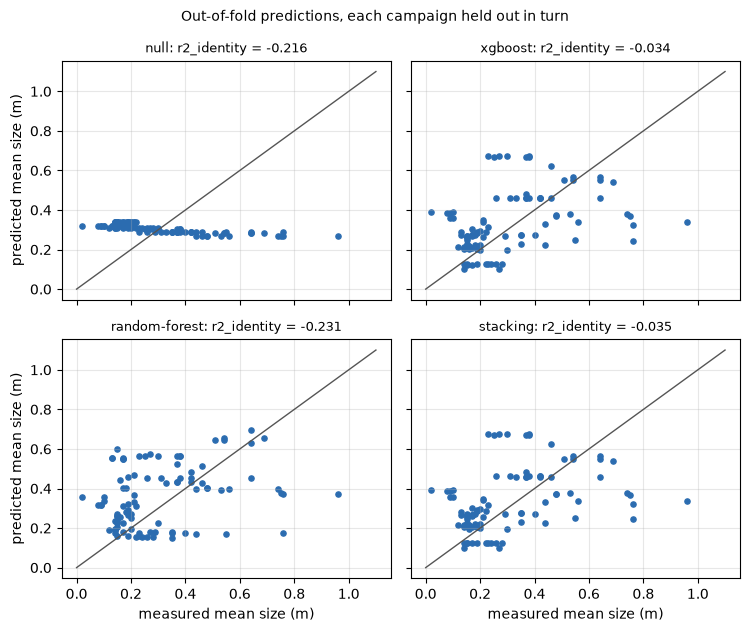

In [4]:
# Score every predictor held out by site with both statistics, and plot predicted against measured
scores = {name: bf.score(tested, predictions[name], method=name) for name in names}
rows = []
for name, s in scores.items():
    pearson = "-" if s.pearson_r2 is None else f"{s.pearson_r2:.4f}"
    rows.append((name, pearson, f"{s.r2_identity:.4f}", f"{s.rmse_m:.4f}"))
show_table(["predictor", "pearson_r2", "r2_identity", "RMSE (m)"], rows)

measured = np.array([blast.x50_m for blast in tested])
fig, axes = plt.subplots(2, 2, figsize=(7.6, 6.4), sharex=True, sharey=True)
for ax, name in zip(axes.ravel(), names):
    predicted = np.array([p.x50_m for p in predictions[name]])
    ax.scatter(measured, predicted, s=14, color="#2b6cb0")
    ax.plot([0, 1.1], [0, 1.1], color="#555", lw=1)
    ax.set_title(f"{name}: r2_identity = {scores[name].r2_identity:.3f}", fontsize=9)
    ax.grid(alpha=0.3)
for ax in axes[1]:
    ax.set_xlabel("measured mean size (m)")
for ax in axes[:, 0]:
    ax.set_ylabel("predicted mean size (m)")
fig.suptitle("Out-of-fold predictions, each campaign held out in turn", fontsize=10)
fig.tight_layout()
plt.show()

By `pearson_r2` the null scores 0.6268 and would rank first of the four, ahead of gradient boosting at 0.1633, the random forest at 0.1034 and stacking at 0.1644. By `r2_identity` it ranks third, at -0.2163 against -0.0342, -0.2315 and -0.0345, and the root-mean-square errors, 0.2067 m, 0.1906 m, 0.2080 m and 0.1906 m, agree with the second ranking. The panels show why: the null is a horizontal line that cuts the identity line, its predictions barely vary, and its squared correlation is high only because they vary in the wrong direction. No learned predictor clears zero, and the random forest is below the null. The figure does not show which campaigns are responsible for the scatter; that is what the jackknife of step 6 isolates.

### Step 4: why the null needs a second look

The null is the training mean, and the training mean moves when a campaign is held out: leaving out a coarse campaign lowers it, leaving out a fine one raises it. The cell lists, for each fold, the mean size of the campaign asked about and the number the null predicts for it, and plots one against the other.

held-out campaign,its mean measured size (m),null prediction: training mean (m)
Akdaglar,0.171,0.341
Dongri-Buzurg,0.413,0.291
Enusa,0.396,0.289
Miami,0.080,0.317
Mrica,0.166,0.320
Murgul,0.311,0.302
Ozmert,0.191,0.311
Reocin,0.616,0.267
Reocin-UG,0.593,0.283
Soma,0.224,0.309


correlation of the null's predictions with the measurements: -0.7917
correlation across the ten folds: -0.8933


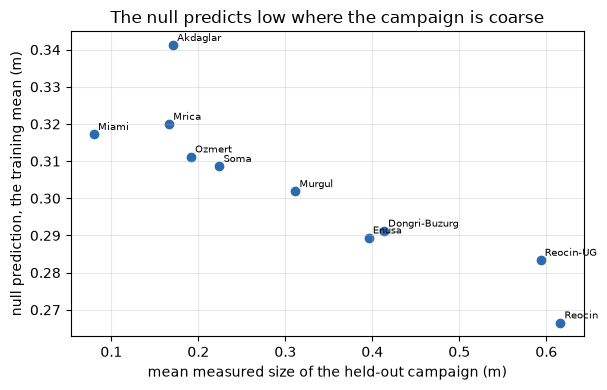

In [5]:
# Why the null is not neutral: its training mean against the campaign it is asked about
rows, held_means, train_means, sites = [], [], [], []
for fold in bf.leave_one_site_out(train):
    sites.append(fold.detail["held_out_site"])
    held_means.append(np.mean([blast.x50_m for blast in fold.test]))
    train_means.append(bf.training_mean(fold.train))
    rows.append((sites[-1], f"{held_means[-1]:.3f}", f"{train_means[-1]:.3f}"))
show_table(["held-out campaign", "its mean measured size (m)", "null prediction: training mean (m)"], rows)
null_values = np.array([p.x50_m for p in predictions["null"]])
print(f"correlation of the null's predictions with the measurements: {np.corrcoef(measured, null_values)[0, 1]:.4f}")
print(f"correlation across the ten folds: {np.corrcoef(held_means, train_means)[0, 1]:.4f}")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.scatter(held_means, train_means, color="#2b6cb0")
for site, x, y in zip(sites, held_means, train_means):
    ax.annotate(site, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlabel("mean measured size of the held-out campaign (m)")
ax.set_ylabel("null prediction, the training mean (m)")
ax.set_title("The null predicts low where the campaign is coarse")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

The ten points fall on a falling line: when Reocin, at 0.616 m, is held out the null predicts 0.267 m, and when Miami, at 0.080 m, is held out it predicts 0.317 m, with a correlation of -0.8933 across the folds and -0.7917 between the pooled predictions and the measurements. The squared value of that last number, 0.6268, is exactly the null's `pearson_r2` of step 3. A coarse campaign pulls the training mean down and a fine one pushes it up, so the null always errs in the direction opposite to the truth. The figure shows the mechanism; it does not show how much of a learned predictor's margin over the null comes from this effect, which is why a margin alone cannot be read as skill and the criterion of the last notebook of this topic needs a score above zero as well.

### Step 5: the interval, resampling blasts and resampling campaigns

`bootstrap_interval` takes a `unit`. With `unit="blast"` each draw resamples the 97 rows with replacement; with `unit="site"` it resamples the ten campaigns, each with all its rows. The cell computes both for the four predictors with 2000 draws and a fixed seed, and draws them side by side.

predictor,unit,r2_identity,low,high,width
null,blast,-0.2163,-0.327,-0.189,0.138
null,site,-0.2163,-1.284,-0.145,1.139
xgboost,blast,-0.0342,-0.382,0.208,0.591
xgboost,site,-0.0342,-2.232,0.418,2.650
random-forest,blast,-0.2315,-0.686,0.054,0.740
random-forest,site,-0.2315,-2.783,0.381,3.164
stacking,blast,-0.0345,-0.383,0.210,0.593
stacking,site,-0.0345,-2.254,0.423,2.677


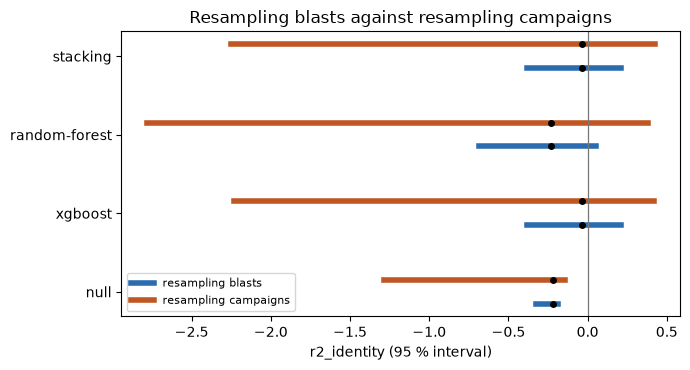

In [6]:
# 95 percent intervals for the four predictors under the two resampling units, 2000 draws
intervals = {}
rows = []
for name in names:
    for unit in ("blast", "site"):
        point, low, high = bf.bootstrap_interval(
            tested, predictions[name], "r2_identity", n_boot=2000, unit=unit, seed=0)
        intervals[name, unit] = (point, low, high)
        rows.append((name, unit, f"{point:.4f}", f"{low:.3f}", f"{high:.3f}", f"{high - low:.3f}"))
show_table(["predictor", "unit", "r2_identity", "low", "high", "width"], rows)

legend = {"blast": "resampling blasts", "site": "resampling campaigns"}
fig, ax = plt.subplots(figsize=(7.0, 3.8))
for row, name in enumerate(names):
    for shift, unit, color in ((-0.15, "blast", "#2b6cb0"), (0.15, "site", "#c05621")):
        point, low, high = intervals[name, unit]
        ax.plot([low, high], [row + shift] * 2, lw=4, color=color, label=legend[unit] if row == 0 else None)
        ax.plot([point], [row + shift], "o", color="black", ms=4)
ax.axvline(0, color="#777", lw=0.9)
ax.set_yticks(range(len(names)), names)
ax.set_xlabel("r2_identity (95 % interval)")
ax.set_title("Resampling blasts against resampling campaigns")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

Resampling blasts gives gradient boosting an interval from -0.382 to 0.208, a width of 0.591, while resampling campaigns gives -2.232 to 0.418, a width of 2.650, and the same widening appears for the random forest (0.740 against 3.164), stacking (0.593 against 2.677) and the null (0.138 against 1.139). The blast interval treats the 97 rows as independent and so looks precise; the campaign interval counts the ten independent units and cannot rule out a score far below zero. Only the null's campaign interval, -1.284 to -0.145, lies wholly under zero. The figure does not say the campaign intervals are exact: a bootstrap of ten units is itself coarse, so the real coverage of the honest interval is itself uncertain.

### Step 6: which campaigns decide the score

A campaign interval is wide when a few campaigns carry the score. To see which, the cell drops each campaign in turn from the pooled out-of-fold predictions of gradient boosting and rescoring the rest.

campaign dropped,r2_identity without it,change
Reocin,-0.2461,-0.2120
Reocin-UG,-0.2273,-0.1931
Akdaglar,-0.1563,-0.1221
Mrica,-0.0767,-0.0425
Enusa,-0.0561,-0.0219
Ozmert,-0.0557,-0.0216
Soma,-0.0283,+0.0059
Dongri-Buzurg,0.0051,+0.0392
Miami,0.0336,+0.0678
Murgul,0.2343,+0.2685


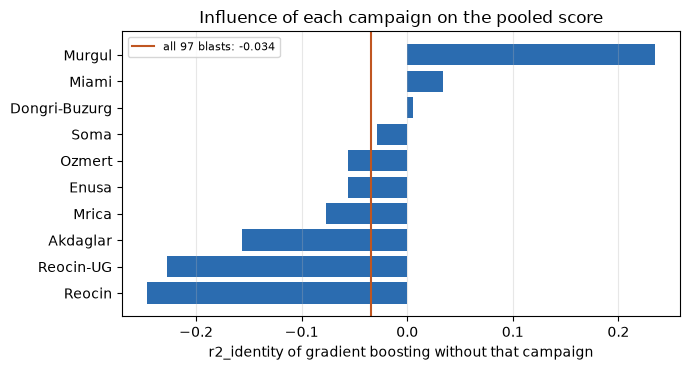

In [7]:
# Why the campaign interval is wide: drop one campaign at a time and rescore gradient boosting
full = bf.score(tested, predictions["xgboost"]).r2_identity
rows = []
for site in sorted({blast.site for blast in tested}):
    keep = [i for i, blast in enumerate(tested) if blast.site != site]
    without = bf.score([tested[i] for i in keep], [predictions["xgboost"][i] for i in keep]).r2_identity
    rows.append((site, without, without - full))
rows.sort(key=lambda row: row[1])
show_table(["campaign dropped", "r2_identity without it", "change"], [(s, f"{w:.4f}", f"{d:+.4f}") for s, w, d in rows])

fig, ax = plt.subplots(figsize=(7.0, 3.8))
ax.barh([row[0] for row in rows], [row[1] for row in rows], color="#2b6cb0")
ax.axvline(full, color="#c05621", lw=1.5, label=f"all 97 blasts: {full:.3f}")
ax.set_xlabel("r2_identity of gradient boosting without that campaign")
ax.set_title("Influence of each campaign on the pooled score")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, axis="x")
fig.tight_layout()
plt.show()

The pooled score of gradient boosting is -0.0342, and removing a single campaign moves it by as much as 0.2685. Without Murgul it is 0.2343, without Miami 0.0336 and without Dongri-Buzurg 0.0051, so the sign of the score depends on whether those campaigns are counted; without Reocin it falls to -0.2461, without Reocin-UG to -0.2273 and without Akdaglar to -0.1563. This is the reason the campaign interval is so wide: the score is carried by a handful of campaigns whose errors differ in size and in sign. The figure does not say why Murgul or Reocin behave as they do; the per-campaign errors of the next notebooks start from there.

## Results

**Answer:** with the campaign held out, a score means something only beside the null and with a campaign interval. The statistic decides the story: on the same 12 hold-out predictions `pearson_r2` is 0.5674 and `r2_identity` is 0.2284, and across the ten campaigns the null has a `pearson_r2` of 0.6268 but an `r2_identity` of -0.2163. Gradient boosting scores -0.0342 and stacking -0.0345, the random forest -0.2315, so no learned predictor is above zero and the forest is below the null. The honest 95 percent interval for gradient boosting resamples campaigns and runs from -2.232 to 0.418, a width of 2.650, against 0.591 when blasts are resampled. One campaign moves the score from -0.0342 to 0.2343 (Murgul) or to -0.2461 (Reocin).

**What this does not show.** It does not decide whether any learned predictor generalises across campaigns, which needs the pre-declared criterion of the last notebook of this topic, and it does not explain why a campaign fails. The null is not a neutral baseline here, since its predictions correlate at -0.7917 with the measurements, so a margin over it is easy to obtain without skill. A bootstrap over ten campaigns is a rough instrument, and the coverage of its interval is itself uncertain.

## Summary

- Report the statistic by name: the same 12 predictions score 0.5674 as `pearson_r2` and 0.2284 as `r2_identity`.
- The null is refitted in every fold and predicts against the truth, so its squared correlation is high and its variance explained negative.
- Resampling campaigns widens gradient boosting's interval from 0.591 to 2.650, because a few campaigns carry the pooled score.
- Next: notebook 03 places a published score in the distribution of its own protocol (level 3).

## References

- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (resampling the independent unit)
- Kulatilake, Hudaverdi and Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (the 12-blast hold-out where two statistics share a name)
- Hudaverdi, Kulatilake and Kuzu 2010, https://doi.org/10.1002/nag.957 (the corpus)
- `blastfrag` 0.4.0, the engine, on PyPI: https://pypi.org/project/blastfrag/